## 1. Налаштування середовища
Порівнюємо п’ять бібліотечних алгоритмів за якістю, стабільністю, часом і пам’яттю з фіксованими параметрами.


In [ ]:
!pip -q install scikit-fuzzy==0.5.0 psutil

In [ ]:
import gc
import os
import time
from threading import Event, Thread
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import DBSCAN, MeanShift, SpectralClustering, AffinityPropagation
from sklearn.datasets import make_blobs, make_moons, load_wine
from sklearn.decomposition import PCA
from sklearn.manifold import spectral_embedding
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score, pairwise_distances
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from skfuzzy.cluster import cmeans
from threadpoolctl import threadpool_limits

SEED = 2026
DELTAS = (0, 0.05, 0.25, 1.0)
REPEATS = 3
NAMES = ['DBSCAN', 'Mean Shift', 'Spectral Clustering', 'Affinity Propagation', 'Fuzzy C-Means']
np.random.seed(SEED)
threads = threadpool_limits(limits=1)
OUT = Path('results')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.dpi': 110, 'axes.titlesize': 10})


## 2. Реалізація алгоритмів кластеризації
Використовуємо scikit-learn для чотирьох методів і scikit-fuzzy для Fuzzy C-Means; число груп для спектрального методу та FCM задаємо як параметр експерименту.


In [ ]:
def run(X, name, s):
    if name == 'Fuzzy C-Means':
        _, U, _, _, history, _, fpc = cmeans(
            X.T, c=s['k'], m=2, error=1e-6, maxiter=500, seed=SEED)
        return U.argmax(axis=0), dict(U=U, history=history, fpc=fpc)
    models = {
        'DBSCAN': lambda: DBSCAN(eps=s['eps'], min_samples=5, n_jobs=1),
        'Mean Shift': lambda: MeanShift(bandwidth=s['h'], n_jobs=1, max_iter=300),
        'Spectral Clustering': lambda: SpectralClustering(
            n_clusters=s['k'], affinity='nearest_neighbors', n_neighbors=15,
            n_init=10, random_state=SEED, n_jobs=1),
        'Affinity Propagation': lambda: AffinityPropagation(
            preference=s['preference'], damping=0.85, max_iter=1000,
            convergence_iter=30, random_state=SEED),
    }
    model = models[name]().fit(X)
    return model.labels_, model

def metrics(X, y, labels):
    mask = labels != -1
    k = len(np.unique(labels[mask]))
    return {'ARI': adjusted_rand_score(y, labels),
            'NMI': normalized_mutual_info_score(y, labels),
            'Силует': silhouette_score(X[mask], labels[mask]) if 1 < k < mask.sum() else np.nan,
            'Кластери': k, 'Шум, %': 100 * np.mean(~mask)}

def scatter(ax, X, labels, title):
    for label in np.unique(labels):
        ax.scatter(*X[labels == label].T, s=10,
                   color='black' if label == -1 else plt.get_cmap('tab20')(int(label) % 20),
                   marker='x' if label == -1 else 'o', alpha=0.8)
    ax.set(title=title, xticks=[], yticks=[])
    ax.set_aspect('equal', adjustable='datalim')

def show(fig, filename):
    fig.savefig(OUT / f'{filename}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)


## 3. Генерація наборів даних
Квадрати формуємо детерміновано, випадкові дані — генераторами PCG64 і MT19937 з нормальним та рівномірним розподілами, а Wine кластеризуємо за всіма 13 стандартизованими ознаками з PCA лише для рисунків.


         Набір             Тип  Точки  Ознаки  k   eps     h  preference
      Квадрати  Детермінований    324       2  4 0.122 0.313      -8.585
        Кільця           PCG64    360       2  2 0.172 0.367     -10.438
        Еліпси           PCG64    360       2  3 0.097 0.215      -8.113
     Півмісяці         MT19937    400       2  2 0.216 0.417     -10.209
Суміш із шумом MT19937 + PCG64    405       2  3 0.142 0.275      -7.722
          Wine        Реальний    178      13  3 3.809 2.654     -47.105


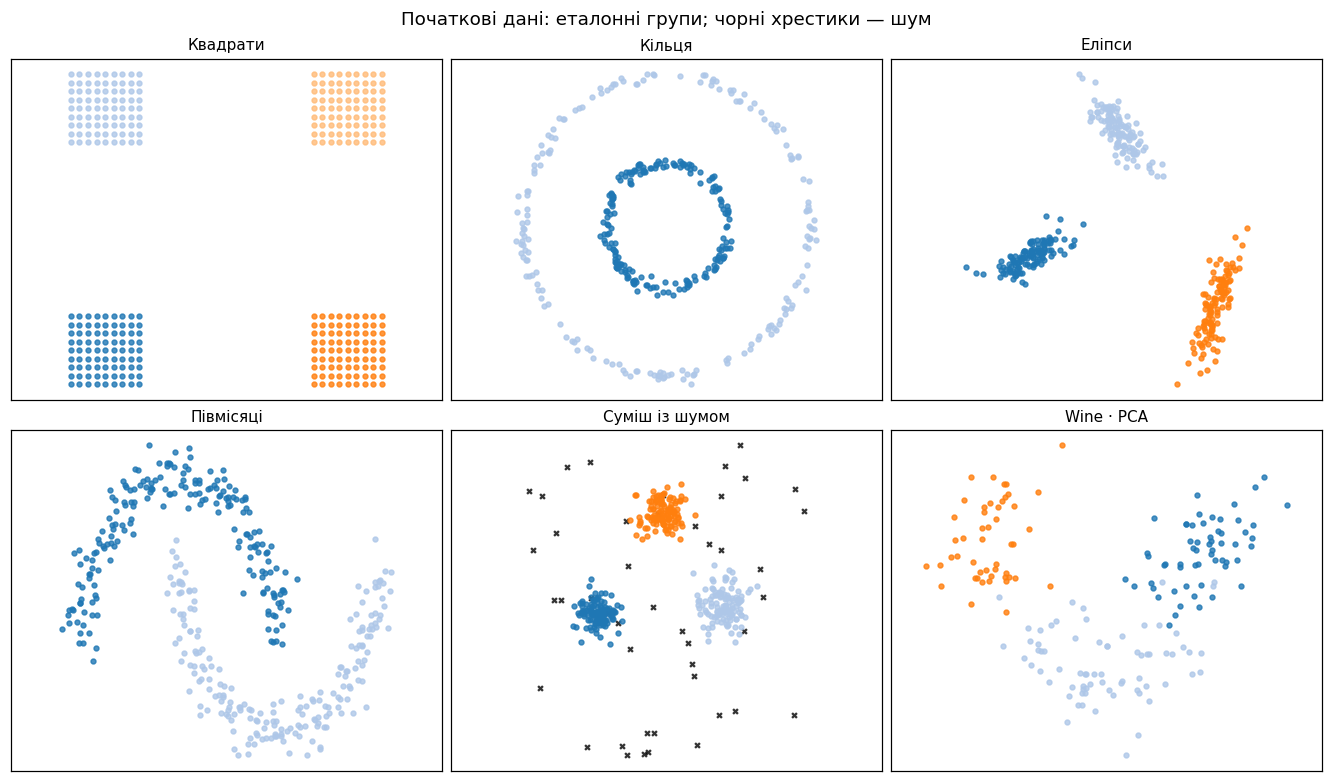

In [ ]:
axis = np.linspace(-0.9, 0.9, 9)
grid = np.array(np.meshgrid(axis, axis)).reshape(2, -1).T
squares = np.vstack([grid + c for c in [(-3.2, -3.2), (-3.2, 3.2), (3.2, -3.2), (3.2, 3.2)]])
rng = np.random.Generator(np.random.PCG64(SEED))
angles = rng.uniform(0, 2 * np.pi, 360)
radii = np.repeat([0.65, 1.55], 180)
circles = np.column_stack([radii * np.cos(angles), radii * np.sin(angles)])
circles += rng.normal(0, 0.035, circles.shape)
ellipses = []
for center, angle in zip([(-4.2, -0.2), (0, 4.1), (4.1, -2.1)], np.deg2rad([22, -43, 68])):
    rotation = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
    ellipses.append((rng.normal(size=(120, 2)) * [1.05, 0.30]) @ rotation.T + center)
mt = np.random.RandomState(SEED)
moons, moons_y = make_moons(n_samples=400, noise=0.08, random_state=mt)
blobs, blobs_y = make_blobs(n_samples=360, centers=[(-3.1, -0.8), (3, -0.5), (0, 3.5)],
                          cluster_std=[0.48, 0.58, 0.52], random_state=mt)
noise = rng.uniform(-7, 7, (45, 2))
wine = load_wine()
raw_data = {
    'Квадрати': (squares, np.repeat(np.arange(4), 81), 4, 1.25, 3.2, 'Детермінований'),
    'Кільця': (circles, np.repeat([0, 1], 180), 2, 1.45, 3.1, 'PCG64'),
    'Еліпси': (np.vstack(ellipses), np.repeat(np.arange(3), 120), 3, 1.35, 3.0, 'PCG64'),
    'Півмісяці': (moons, moons_y, 2, 1.55, 3.0, 'MT19937'),
    'Суміш із шумом': (np.vstack([blobs, noise]), np.r_[blobs_y, np.full(45, -1)],
                       3, 1.55, 3.0, 'MT19937 + PCG64'),
    'Wine': (wine.data, wine.target, 3, 1.65, 1.15, 'Реальний'),
}
DATA = {}
for key, (raw, y, k, db, ms, kind) in raw_data.items():
    X = StandardScaler().fit_transform(raw)
    distances = NearestNeighbors(n_neighbors=6).fit(X).kneighbors(X)[0]
    d5 = np.median(distances[:, 5])
    pca = PCA(n_components=2, random_state=SEED).fit(X) if X.shape[1] > 2 else None
    similarities = -pairwise_distances(X, squared=True)
    DATA[key] = dict(X=X, y=y, k=k, kind=kind, d5=d5, eps=db*d5, h=ms*d5,
                     preference=np.quantile(similarities[~np.eye(len(X), dtype=bool)], 0.08),
                     view=X if pca is None else pca.transform(X), pca=pca)

print(pd.DataFrame([{'Набір': key, 'Тип': s['kind'], 'Точки': len(s['X']),
                      'Ознаки': s['X'].shape[1], 'k': s['k'],
                      'eps': s['eps'], 'h': s['h'], 'preference': s['preference']}
                     for key, s in DATA.items()]).round(3).to_string(index=False))
fig, axes = plt.subplots(2, 3, figsize=(12, 7), constrained_layout=True)
for ax, (key, s) in zip(axes.flat, DATA.items()):
    scatter(ax, s['view'], s['y'], key + (' · PCA' if key == 'Wine' else ''))
fig.suptitle('Початкові дані: еталонні групи; чорні хрестики — шум')
show(fig, '01_dani')


## 4. Кластеризація та порівняння результатів
ARI й NMI порівнюємо з еталоном, силует обчислюємо без шуму −1, а невизначений силует залишаємо порожнім.


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


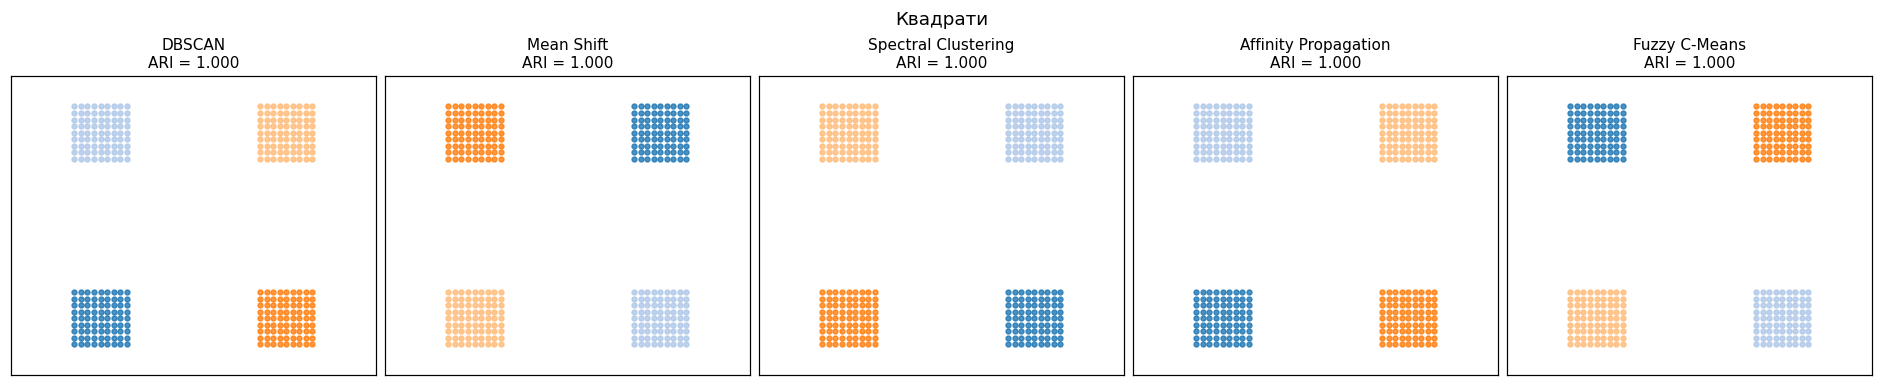

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


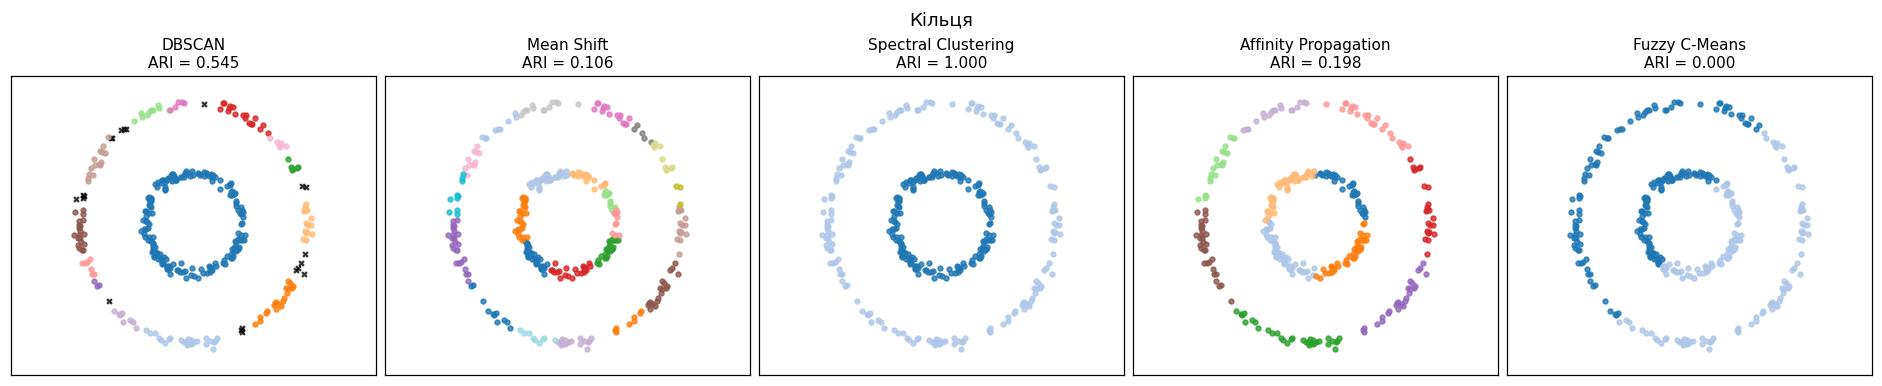

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


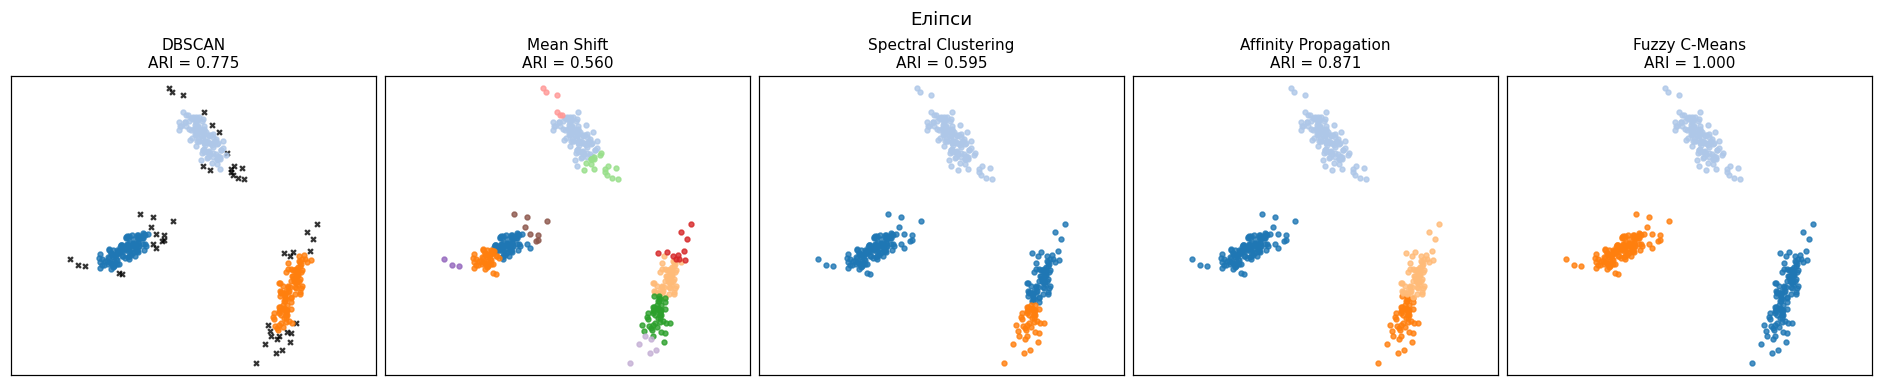

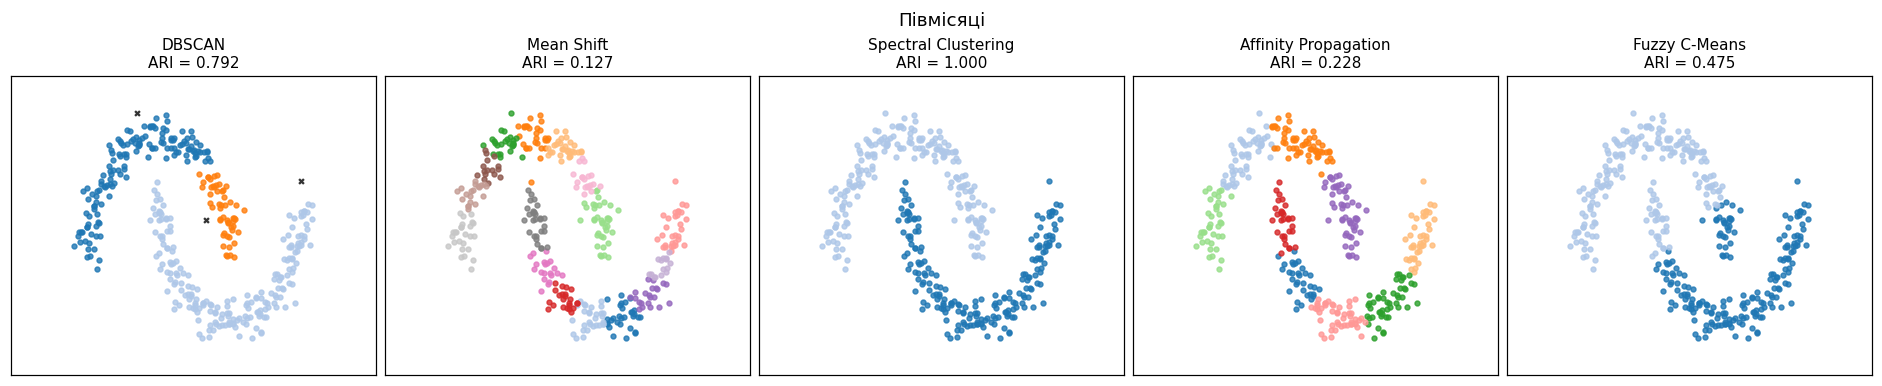

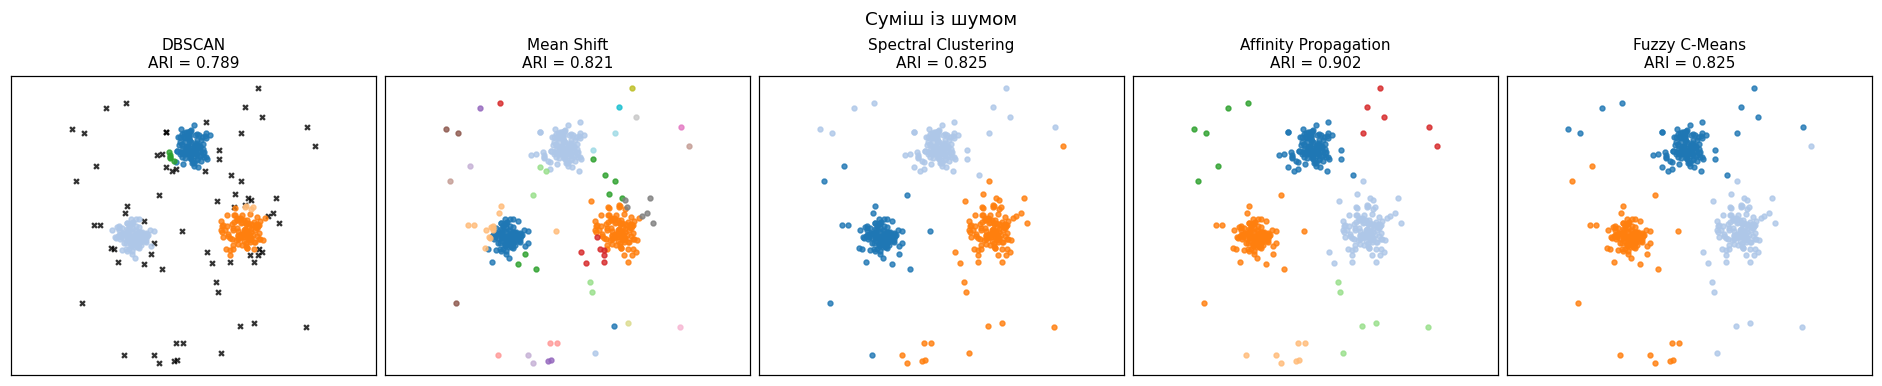

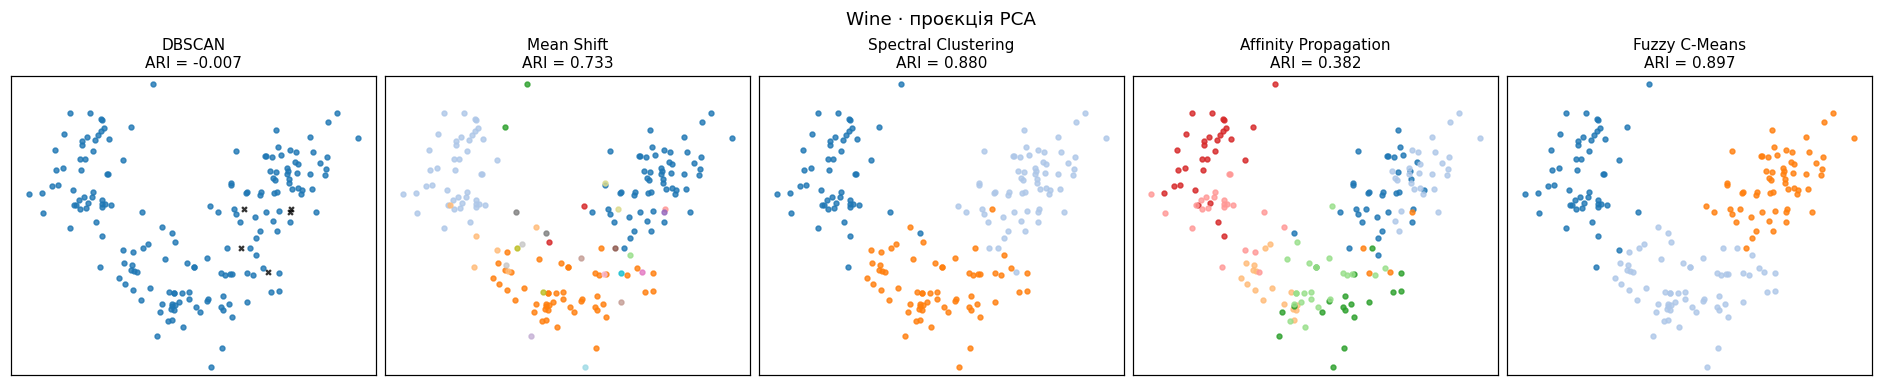

         Набір             Алгоритм    ARI   NMI  Силует  Кластери  Шум, %
      Квадрати               DBSCAN  1.000 1.000   0.825         4   0.000
      Квадрати           Mean Shift  1.000 1.000   0.825         4   0.000
      Квадрати  Spectral Clustering  1.000 1.000   0.825         4   0.000
      Квадрати Affinity Propagation  1.000 1.000   0.825         4   0.000
      Квадрати        Fuzzy C-Means  1.000 1.000   0.825         4   0.000
        Кільця               DBSCAN  0.545 0.528   0.328        14   5.833
        Кільця           Mean Shift  0.106 0.375   0.484        23   0.000
        Кільця  Spectral Clustering  1.000 1.000   0.151         2   0.000
        Кільця Affinity Propagation  0.198 0.457   0.538        11   0.000
        Кільця        Fuzzy C-Means  0.000 0.002   0.339         2   0.000
        Еліпси               DBSCAN  0.775 0.771   0.850         3  14.167
        Еліпси           Mean Shift  0.560 0.711   0.392        11   0.000
        Еліпси  Spectral 

In [ ]:
RESULTS, rows = {}, []
for key, s in DATA.items():
    fig, axes = plt.subplots(1, 5, figsize=(17, 3.4), constrained_layout=True)
    for ax, name in zip(axes, NAMES):
        labels, info = run(s['X'], name, s)
        RESULTS[key, name] = (labels, info)
        score = metrics(s['X'], s['y'], labels)
        rows.append({'Набір': key, 'Алгоритм': name, **score})
        scatter(ax, s['view'], labels, f'{name}\nARI = {score["ARI"]:.3f}')
    fig.suptitle(key + (' · проєкція PCA' if key == 'Wine' else ''))
    show(fig, f'02_klastery_{list(DATA).index(key)}')
quality = pd.DataFrame(rows)
print(quality.round(3).to_string(index=False))


Бібліотечні моделі відкривають ядрові точки, моди, граф сусідства, представників і історію FCM для візуалізації проміжних результатів.


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


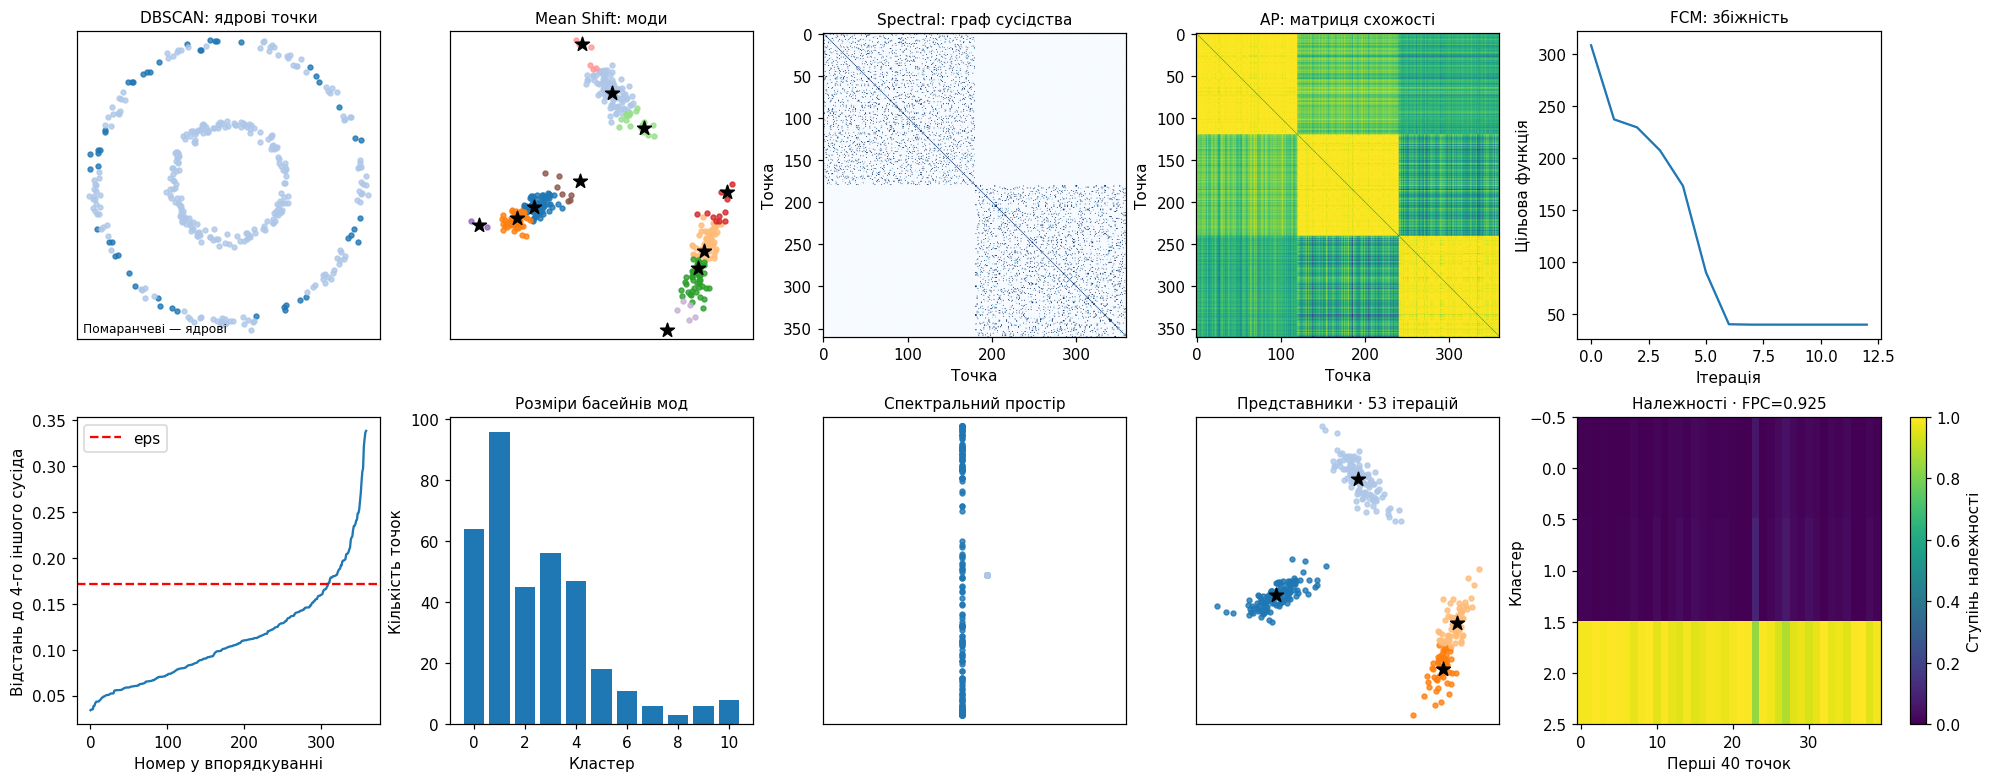

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7), constrained_layout=True)
for j, name in enumerate(NAMES):
    key = 'Кільця' if name in ('DBSCAN', 'Spectral Clustering') else 'Еліпси'
    s = DATA[key]
    X = s['X']
    labels, info = RESULTS[key, name]
    a, b = axes[:, j]
    if name == 'DBSCAN':
        core = np.zeros(len(X), dtype=int)
        core[info.core_sample_indices_] = 1
        scatter(a, X, core, 'DBSCAN: ядрові точки')
        a.text(0.02, 0.02, 'Помаранчеві — ядрові', transform=a.transAxes, fontsize=8)
        distances = NearestNeighbors(n_neighbors=5).fit(X).kneighbors(X)[0][:, -1]
        b.plot(np.sort(distances))
        b.axhline(s['eps'], color='red', ls='--', label='eps')
        b.set(xlabel='Номер у впорядкуванні', ylabel='Відстань до 4-го іншого сусіда')
        b.legend()
    elif name == 'Mean Shift':
        scatter(a, X, labels, 'Mean Shift: моди')
        a.scatter(*info.cluster_centers_.T, c='black', marker='*', s=90)
        b.bar(*np.unique(labels, return_counts=True))
        b.set(xlabel='Кластер', ylabel='Кількість точок', title='Розміри басейнів мод')
    elif name == 'Spectral Clustering':
        a.imshow(info.affinity_matrix_.toarray(), cmap='Blues')
        a.set(title='Spectral: граф сусідства', xlabel='Точка', ylabel='Точка')
        embedding = spectral_embedding(info.affinity_matrix_, n_components=2, random_state=SEED)
        scatter(b, embedding, labels, 'Спектральний простір')
    elif name == 'Affinity Propagation':
        a.imshow(info.affinity_matrix_, cmap='viridis')
        a.set(title='AP: матриця схожості', xlabel='Точка', ylabel='Точка')
        scatter(b, X, labels, f'Представники · {info.n_iter_} ітерацій')
        b.scatter(*X[info.cluster_centers_indices_].T, c='black', marker='*', s=90)
    else:
        a.plot(info['history'])
        a.set(title='FCM: збіжність', xlabel='Ітерація', ylabel='Цільова функція')
        image = b.imshow(info['U'][:, :40], aspect='auto', vmin=0, vmax=1, cmap='viridis')
        b.set(title=f'Належності · FPC={info["fpc"]:.3f}', xlabel='Перші 40 точок', ylabel='Кластер')
        fig.colorbar(image, ax=b, label='Ступінь належності')
show(fig, '03_promizhni_rezultaty')


## 5. Дослідження стабільності кластеризації
Три точки на квантилях 20%, 50% і 80% першої координати рисунка зміщуємо окремо та разом на δ = αd₅ у фіксованих напрямках, зберігаючи масштабування, seed і параметри моделей.


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ma

                           Мін. ARI решти  Сер. ARI решти  Макс. змінено, %
Алгоритм             α                                                     
Affinity Propagation 0.00          1.0000          1.0000            0.0000
                     0.05          1.0000          1.0000            0.0000
                     0.25          1.0000          1.0000            0.0000
                     1.00          0.9328          0.9944            3.0227
DBSCAN               0.00          1.0000          1.0000            0.0000
                     0.05          1.0000          1.0000            0.0000
                     0.25          1.0000          1.0000            0.0000
                     1.00          0.9940          0.9995            0.2801
Fuzzy C-Means        0.00          1.0000          1.0000            0.0000
                     0.05          1.0000          1.0000            0.0000
                     0.25          1.0000          1.0000            0.0000
            

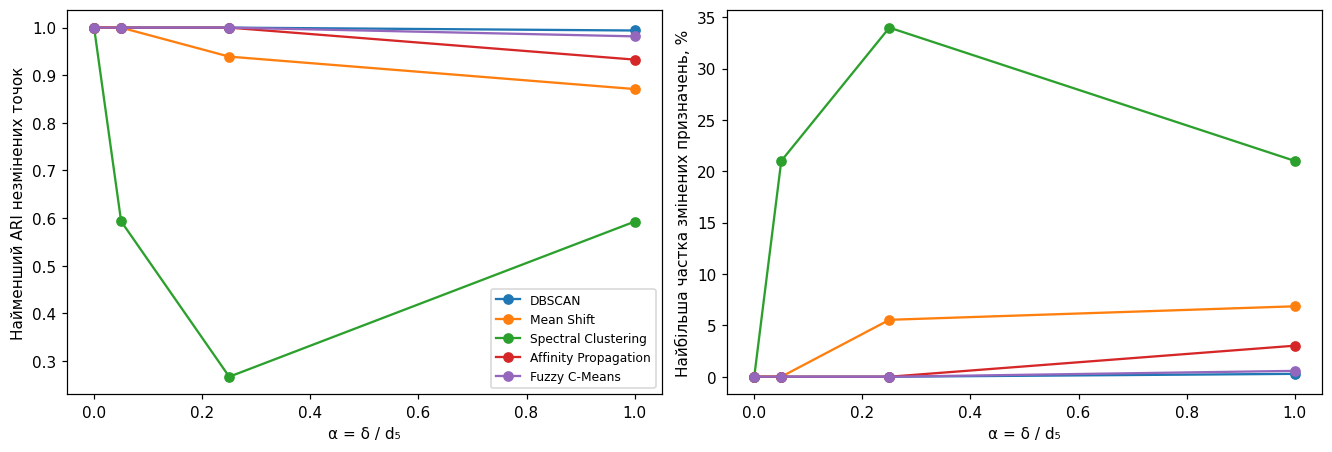

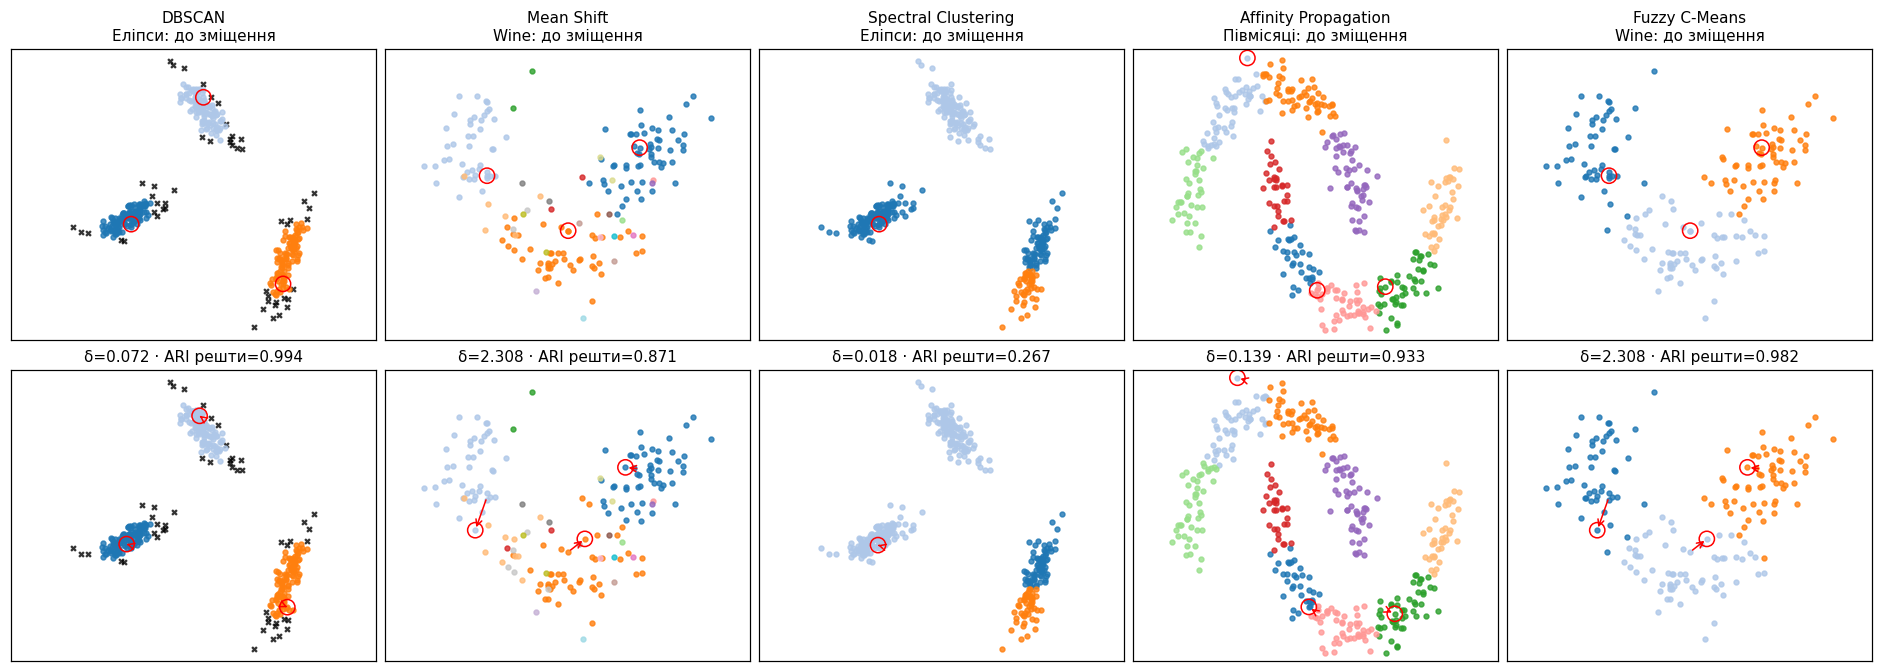

In [ ]:
def align_labels(old, new):
    a, b = np.unique(old[old != -1]), np.unique(new[new != -1])
    counts = np.array([[np.sum((old == x) & (new == y)) for y in b] for x in a]).reshape(len(a), len(b))
    i, j = linear_sum_assignment(-counts)
    mapping = {-1: -1, **{label: int(old.max()) + 1 + t for t, label in enumerate(b)}}
    mapping.update({b[y]: a[x] for x, y in zip(i, j)})
    return np.array([mapping[label] for label in new])

stability_rows, worst = [], {}
for key, s in DATA.items():
    X = s['X']
    order = np.argsort(s['view'][:, 0])
    points = order[(np.array([0.2, 0.5, 0.8]) * (len(X) - 1)).astype(int)]
    directions = np.random.default_rng(SEED).normal(size=(3, X.shape[1]))
    directions /= np.linalg.norm(directions, axis=1, keepdims=True)
    groups = [(str(p), np.array([p]), directions[[i]]) for i, p in enumerate(points)]
    groups.append(('Три разом', points, directions))
    for group, indices, vectors in groups:
        untouched = np.ones(len(X), dtype=bool)
        untouched[indices] = False
        for alpha in DELTAS:
            delta = alpha * s['d5']
            modified = X.copy()
            modified[indices] += delta * vectors
            for name in NAMES:
                old = RESULTS[key, name][0]
                new, _ = run(modified, name, s)
                aligned = align_labels(old, new)
                score = adjusted_rand_score(old[untouched], new[untouched])
                stability_rows.append({'Набір': key, 'Алгоритм': name, 'Точки': group,
                    'α': alpha, 'δ': delta, 'ARI всіх': adjusted_rand_score(old, new),
                    'ARI решти': score, 'Змінено решти, %': 100*np.mean(old[untouched] != aligned[untouched]),
                    'Δk': len(set(new)-{-1}) - len(set(old)-{-1}),
                    'Δшум, в.п.': 100*(np.mean(new == -1)-np.mean(old == -1))})
                if alpha > 0 and (name not in worst or score < worst[name]['score']):
                    worst[name] = dict(score=score, key=key, X=modified, labels=aligned,
                                       indices=indices.copy(), delta=delta)
stability = pd.DataFrame(stability_rows)
print(stability.groupby(['Алгоритм', 'α']).agg(
    **{'Мін. ARI решти': ('ARI решти', 'min'), 'Сер. ARI решти': ('ARI решти', 'mean'),
       'Макс. змінено, %': ('Змінено решти, %', 'max')}).round(4).to_string())
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name in NAMES:
    table = stability[stability['Алгоритм'] == name].groupby('α')
    axes[0].plot(DELTAS, table['ARI решти'].min(), 'o-', label=name)
    axes[1].plot(DELTAS, table['Змінено решти, %'].max(), 'o-')
axes[0].set(xlabel='α = δ / d₅', ylabel='Найменший ARI незмінених точок')
axes[1].set(xlabel='α = δ / d₅', ylabel='Найбільша частка змінених призначень, %')
axes[0].legend(fontsize=8)
show(fig, '04_stabilnist')

fig, axes = plt.subplots(2, 5, figsize=(17, 6), constrained_layout=True)
for j, name in enumerate(NAMES):
    w = worst[name]
    s = DATA[w['key']]
    view = w['X'] if s['pca'] is None else s['pca'].transform(w['X'])
    scatter(axes[0, j], s['view'], RESULTS[w['key'], name][0], f'{name}\n{w["key"]}: до зміщення')
    scatter(axes[1, j], view, w['labels'], f'δ={w["delta"]:.3f} · ARI решти={w["score"]:.3f}')
    for p in w['indices']:
        axes[0, j].scatter(*s['view'][p], s=100, facecolors='none', edgecolors='red')
        axes[1, j].scatter(*view[p], s=100, facecolors='none', edgecolors='red')
        axes[1, j].annotate('', xy=view[p], xytext=s['view'][p],
                            arrowprops=dict(arrowstyle='->', color='red'))
show(fig, '05_naigirshi_zminy')


## 6. Вимірювання продуктивності
Час — медіана трьох запусків після прогріву без метрик і рисунків, RAM — максимум RSS поточного процесу та приріст над RSS перед fit з опитуванням щомілісекунди, тому короткі піки й повторне використання пам’яті можуть занижувати приріст.


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ma

         Набір             Алгоритм  Час, мс  Пік RSS, MiB  Приріст RSS, MiB
      Квадрати               DBSCAN    3.053       365.367             0.004
      Квадрати           Mean Shift 1020.497       365.367             0.004
      Квадрати  Spectral Clustering   26.248       365.367             0.004
      Квадрати Affinity Propagation   83.338       365.367             0.004
      Квадрати        Fuzzy C-Means    5.897       365.367             0.004
        Кільця               DBSCAN    4.764       365.367             0.004
        Кільця           Mean Shift  960.578       365.367             0.004
        Кільця  Spectral Clustering   37.764       365.367             0.004
        Кільця Affinity Propagation   88.863       365.367             0.004
        Кільця        Fuzzy C-Means   81.337       365.367             0.004
        Еліпси               DBSCAN    3.127       365.367             0.004
        Еліпси           Mean Shift 1529.431       365.367             0.004

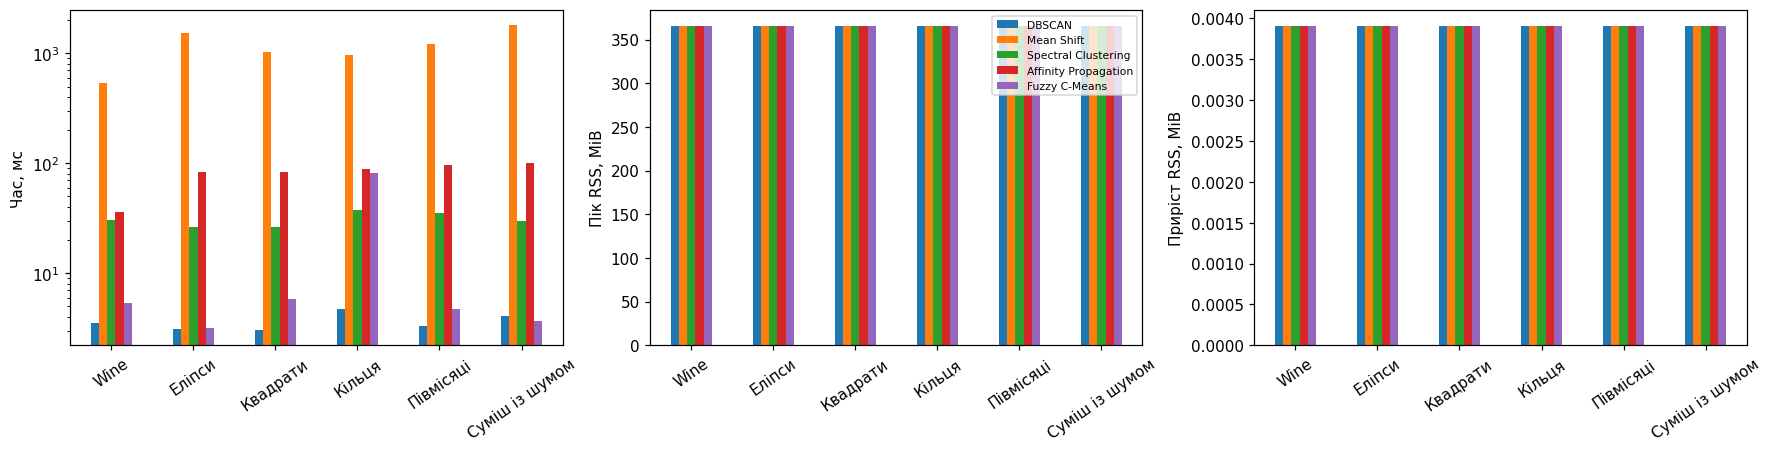

In [ ]:
def measure_ram(X, name, s):
    process = psutil.Process(os.getpid())
    baseline = process.memory_info().rss
    samples = [baseline]
    stop = Event()
    def sample():
        while not stop.wait(0.001):
            samples.append(process.memory_info().rss)
    sampler = Thread(target=sample)
    sampler.start()
    try:
        result = run(X, name, s)
        samples.append(process.memory_info().rss)
    finally:
        stop.set()
        sampler.join()
    peak = max(samples)
    return peak / 2**20, (peak - baseline) / 2**20

performance_rows = []
for key, s in DATA.items():
    for name in NAMES:
        run(s['X'], name, s)
        times = []
        for _ in range(REPEATS):
            gc.collect()
            start = time.perf_counter()
            run(s['X'], name, s)
            times.append(1000 * (time.perf_counter() - start))
        gc.collect()
        peak, extra = measure_ram(s['X'], name, s)
        performance_rows.append({'Набір': key, 'Алгоритм': name, 'Час, мс': np.median(times),
                                 'Пік RSS, MiB': peak, 'Приріст RSS, MiB': extra})
performance = pd.DataFrame(performance_rows)
print(performance.round(3).to_string(index=False))
fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
for ax, column in zip(axes, ['Час, мс', 'Пік RSS, MiB', 'Приріст RSS, MiB']):
    performance.pivot(index='Набір', columns='Алгоритм', values=column)[NAMES].plot.bar(ax=ax)
    ax.set(ylabel=column, xlabel='')
    ax.tick_params(axis='x', rotation=35)
    ax.get_legend().remove()
axes[0].set_yscale('log')
axes[1].legend(fontsize=7)
show(fig, '06_produktyvnist')


## 7. Підсумкове порівняння
Підсумки стосуються цих наборів і параметрів: задане k допомагає спектральному методу та FCM, а стабільність сама по собі не гарантує правильності кластерів.


                        ARI    NMI  Силует  Мін. ARI решти  Сума часу, мс  Макс. RSS, MiB  Макс. приріст RSS, MiB
Алгоритм                                                                                                         
DBSCAN                0.649  0.651   0.555           0.994         21.862         365.375                   0.004
Mean Shift            0.558  0.654   0.434           0.871       7064.774         365.375                   0.004
Spectral Clustering   0.883  0.898   0.457           0.267        185.632         365.375                   0.004
Affinity Propagation  0.597  0.710   0.574           0.933        488.420         365.375                   0.004
Fuzzy C-Means         0.700  0.677   0.578           0.982        104.282         365.375                   0.004


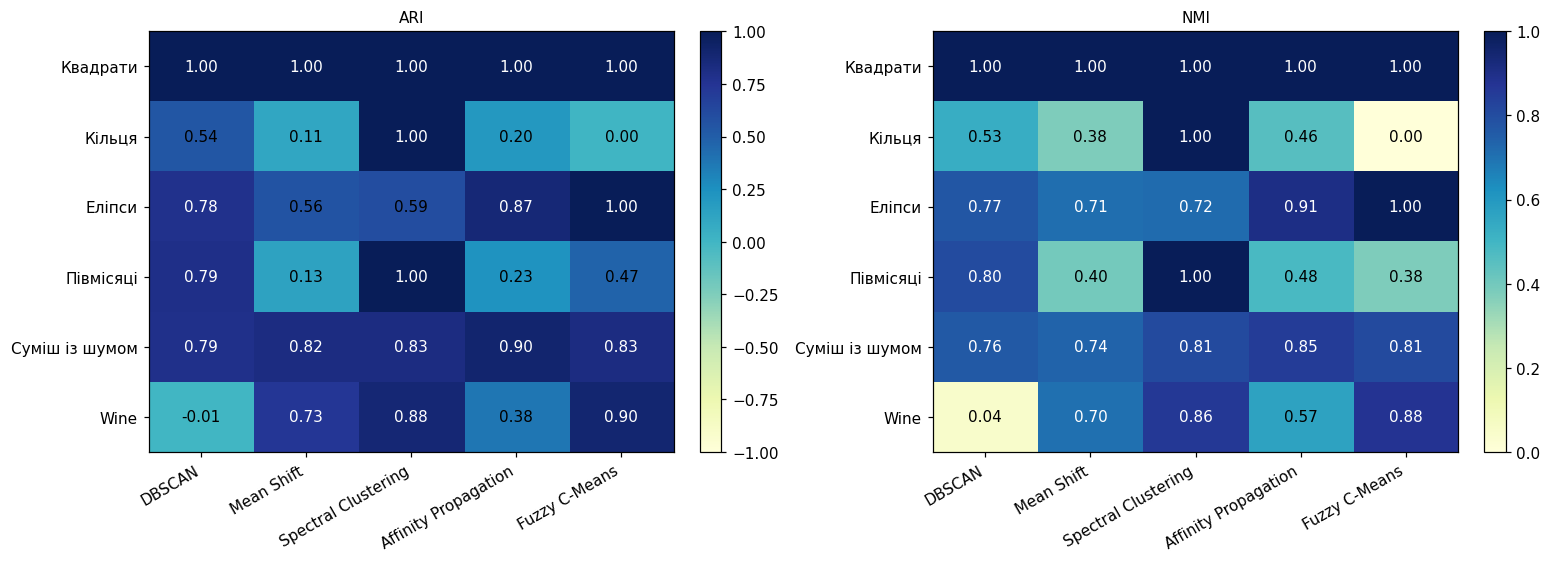

In [ ]:
summary = quality.groupby('Алгоритм')[['ARI', 'NMI', 'Силует']].mean().reindex(NAMES)
summary['Мін. ARI решти'] = stability.groupby('Алгоритм')['ARI решти'].min()
summary['Сума часу, мс'] = performance.groupby('Алгоритм')['Час, мс'].sum()
summary['Макс. RSS, MiB'] = performance.groupby('Алгоритм')['Пік RSS, MiB'].max()
summary['Макс. приріст RSS, MiB'] = performance.groupby('Алгоритм')['Приріст RSS, MiB'].max()
print(summary.round(3).to_string())
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for ax, column in zip(axes, ['ARI', 'NMI']):
    table = quality.pivot(index='Набір', columns='Алгоритм', values=column).reindex(DATA)[NAMES]
    image = ax.imshow(table, vmin=-1 if column == 'ARI' else 0, vmax=1, cmap='YlGnBu', aspect='auto')
    ax.set(title=column, xticks=range(5), yticks=range(len(DATA)), yticklabels=table.index)
    ax.set_xticklabels(NAMES, rotation=30, ha='right')
    for (i, j), value in np.ndenumerate(table.to_numpy()):
        ax.text(j, i, f'{value:.2f}', ha='center', va='center', color='white' if value > 0.65 else 'black')
    fig.colorbar(image, ax=ax)
show(fig, '07_yakist')

for filename, table in [('yakist', quality), ('stabilnist', stability),
                        ('produktyvnist', performance), ('pidsumok', summary.reset_index())]:
    table.to_csv(OUT / f'{filename}.csv', index=False, encoding='utf-8-sig')
